# Leakage-safe transaction-history features for overdraft synthesis

This notebook processes the **raw transaction history** and adds contextual features to each transaction before it is supplied to ClavaDDPM. The goal is to make information relevant to overdrafts more explicit—for example, recent account cash-flow patterns and prior overdraft history—so the generator has more useful context than isolated transaction attributes.

The target used in the detection analysis is `balance < 0`. The current transaction's `balance` is **never used to construct any added feature**. Historical overdraft features use only transactions from earlier calendar dates; all transactions on the current date are excluded from that row's history. `balance` remains in the ClavaDDPM transaction table because it is needed to derive the label in downstream evaluation; it must not be used as an input to a supervised detector.

The notebook writes to a new data directory (default `multi_table/data/berka_feature_engineered`) and leaves the existing preprocessed inputs untouched. The output contains all tables and metadata needed by `load_tables`, with added continuous features in `trans.csv` and `trans_domain.json`.

In [1]:
import json
import os
import pickle
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display as display_dataframe


def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root from this notebook's working directory."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml in this directory or its parents.")


ROOT = find_project_root()
os.chdir(ROOT)
MULTI_TABLE_DIR = ROOT / "implementations/tabular_data/multi_table"
RAW_TRANS_PATH = MULTI_TABLE_DIR / "data/berka/raw_data/trans.csv"
BASE_DATA_DIR = Path(os.environ.get("BERKA_BASE_DATA_DIR", MULTI_TABLE_DIR / "data/berka2"))
OUTPUT_DIR = Path(
    os.environ.get("BERKA_FEATURE_OUTPUT_DIR", MULTI_TABLE_DIR / "data/berka_feature_engineered"),
)
PREPROCESS_META_PATH = BASE_DATA_DIR / "preprocess_meta.json"
ENCODERS_PATH = BASE_DATA_DIR / "label_encoders.pkl"

for required_path in (RAW_TRANS_PATH, BASE_DATA_DIR / "trans.csv", PREPROCESS_META_PATH, ENCODERS_PATH):
    if not required_path.is_file():
        raise FileNotFoundError(f"Required raw/preprocessed input was not found: {required_path}")
if OUTPUT_DIR.resolve() == BASE_DATA_DIR.resolve():
    raise ValueError("OUTPUT_DIR must be separate from BASE_DATA_DIR so existing inputs are preserved.")

print(f"Raw transactions: {RAW_TRANS_PATH}")
print(f"Base ClavaDDPM inputs: {BASE_DATA_DIR}")
print(f"Feature-engineered output: {OUTPUT_DIR}")

Raw transactions: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka/raw_data/trans.csv
Base ClavaDDPM inputs: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka2
Feature-engineered output: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka_feature_engineered


## Feature definitions and leakage boundaries

Features are computed on a per-account timeline, using daily aggregates and a strict **past-only** window `[transaction date - window, transaction date)`. Same-day transactions are deliberately excluded because the source has date but no reliable within-day timestamp.

Added features:

- Calendar context: weekday and month represented with sine/cosine pairs.
- Prior activity: days since the previous active date; transaction counts and average amount over the previous 7 and 30 calendar days.
- Prior cash flow: previous 7/30-day inflow, outflow, and net flow (inflow minus outflow). `PRIJEM` is treated as inflow; the remaining observed transaction types are treated as outflow.
- Prior overdraft history: count and rate of overdraft transactions in the previous 30 calendar days. These use earlier transaction balances only; they do not use the current row's balance or current overdraft label.
- Relative current amount: current transaction amount divided by the account's mean amount in the previous 30 days. Current amount is an observed transaction feature, not the overdraft label.

If no prior history exists, history sums/counts/rates are zero and the elapsed-day feature is zero; counts indicate whether history exists. Validate these semantics for downstream use. Do not construct rolling features over an unsorted dataset or include current-day outcomes.

In [2]:
from implementations.tabular_data.multi_table.data_preprocessing.pre_process_berka_all_tabels import (
    load_raw_table,
    preprocess_table,
)


raw_trans = load_raw_table(RAW_TRANS_PATH, "trans").reset_index(drop=True)
with PREPROCESS_META_PATH.open(encoding="utf-8") as file:
    preprocess_meta = json.load(file)
with ENCODERS_PATH.open("rb") as file:
    preprocessing_artifacts = pickle.load(file)

trans_date_epoch = preprocess_meta["date_epochs_yymmdd"]["trans"]
saved_trans_encoders = preprocessing_artifacts["encoders"]["trans"]
print(f"Loaded {len(raw_trans):,} raw transactions across {raw_trans['account_id'].nunique():,} accounts.")
print("Saved transaction date epoch:", trans_date_epoch)
display_dataframe(raw_trans.head())

Loaded 1,056,320 raw transactions across 4,500 accounts.
Saved transaction date epoch: 930101


,trans_id,account_id,date,type,operation,amount,balance,k_symbol,bank,account
0,695247,2378,930101,PRIJEM,VKLAD,700.0,700.0,NaN,NaN,NaN
1,171812,576,930101,PRIJEM,VKLAD,900.0,900.0,NaN,NaN,NaN
2,207264,704,930101,PRIJEM,VKLAD,1000.0,1000.0,NaN,NaN,NaN
3,1117247,3818,930101,PRIJEM,VKLAD,600.0,600.0,NaN,NaN,NaN
4,579373,1972,930102,PRIJEM,VKLAD,400.0,400.0,NaN,NaN,NaN


In [3]:
def _prior_window_sum(
    account_days: np.ndarray,
    transaction_days: np.ndarray,
    prior_day_positions: np.ndarray,
    cumulative: dict[str, np.ndarray],
    *,
    column: str,
    window_days: int,
) -> np.ndarray:
    """Sum daily values in [current date - window, current date)."""
    start_positions = np.searchsorted(account_days, transaction_days - window_days, side="left")
    return cumulative[column][prior_day_positions] - cumulative[column][start_positions]


def build_prior_only_features(raw: pd.DataFrame) -> pd.DataFrame:  # noqa: PLR0915
    """Build transaction features from current observables and strictly prior dates."""
    required = {"trans_id", "account_id", "date", "type", "amount", "balance"}
    missing = required.difference(raw.columns)
    if missing:
        raise ValueError(f"Raw transactions are missing required columns: {sorted(missing)}")
    if raw["trans_id"].duplicated().any():
        raise ValueError("trans_id must uniquely identify transaction rows for a safe join.")

    work = raw.reset_index(drop=True).copy()
    amounts = pd.to_numeric(work["amount"], errors="raise").to_numpy(dtype=float)
    balances = pd.to_numeric(work["balance"], errors="raise").to_numpy(dtype=float)
    dates = pd.to_datetime(work["date"].astype(str), format="%y%m%d", errors="raise")
    day_numbers = dates.to_numpy(dtype="datetime64[D]").astype("int64")
    types = work["type"].fillna("").astype(str)
    is_inflow = types.eq("PRIJEM").to_numpy()

    # Row-level data are reduced to daily aggregates before features are assigned.
    work["_day"] = day_numbers
    work["_tx_count"] = 1.0
    work["_inflow"] = np.where(is_inflow, amounts, 0.0)
    work["_outflow"] = np.where(is_inflow, 0.0, amounts)
    work["_amount_sum"] = amounts
    work["_overdraft_count"] = (balances < 0).astype(float)
    daily = (
        work.groupby(["account_id", "_day"], sort=True)
        .agg(
            tx_count=("_tx_count", "sum"),
            inflow=("_inflow", "sum"),
            outflow=("_outflow", "sum"),
            amount_sum=("_amount_sum", "sum"),
            overdraft_count=("_overdraft_count", "sum"),
        )
        .sort_index()
    )

    n_rows = len(work)
    features = pd.DataFrame(index=work.index)
    weekday = dates.dt.dayofweek.to_numpy(dtype=float)
    month = dates.dt.month.to_numpy(dtype=float) - 1
    features["calendar_weekday_sin"] = np.sin(2 * np.pi * weekday / 7)
    features["calendar_weekday_cos"] = np.cos(2 * np.pi * weekday / 7)
    features["calendar_month_sin"] = np.sin(2 * np.pi * month / 12)
    features["calendar_month_cos"] = np.cos(2 * np.pi * month / 12)

    for feature in (
        "history_days_since_previous_active_day",
        "history_prior_7d_transaction_count",
        "history_prior_7d_inflow",
        "history_prior_7d_outflow",
        "history_prior_7d_net_flow",
        "history_prior_30d_transaction_count",
        "history_prior_30d_inflow",
        "history_prior_30d_outflow",
        "history_prior_30d_net_flow",
        "history_prior_30d_mean_amount",
        "history_prior_30d_overdraft_count",
        "history_prior_30d_overdraft_rate",
    ):
        features[feature] = np.zeros(n_rows, dtype=float)

    for account_id, row_positions in work.groupby("account_id", sort=False).indices.items():
        account_daily = daily.loc[account_id]
        account_days = account_daily.index.to_numpy(dtype="int64")
        transaction_days = day_numbers[row_positions]
        prior_day_positions = np.searchsorted(account_days, transaction_days, side="left")
        has_prior_day = prior_day_positions > 0
        prior_positions = np.maximum(prior_day_positions - 1, 0)
        features.loc[row_positions[has_prior_day], "history_days_since_previous_active_day"] = (
            transaction_days[has_prior_day] - account_days[prior_positions[has_prior_day]]
        )

        cumulative: dict[str, np.ndarray] = {}
        for column in ("tx_count", "inflow", "outflow", "amount_sum", "overdraft_count"):
            cumulative[column] = np.concatenate(
                ([0.0], np.cumsum(account_daily[column].to_numpy(dtype=float))),
            )

        history: dict[str, np.ndarray] = {}
        for window in (7, 30):
            history[f"{window}d_transaction_count"] = _prior_window_sum(
                account_days, transaction_days, prior_day_positions, cumulative,
                column="tx_count", window_days=window,
            )
            history[f"{window}d_inflow"] = _prior_window_sum(
                account_days, transaction_days, prior_day_positions, cumulative,
                column="inflow", window_days=window,
            )
            history[f"{window}d_outflow"] = _prior_window_sum(
                account_days, transaction_days, prior_day_positions, cumulative,
                column="outflow", window_days=window,
            )
            history[f"{window}d_net_flow"] = (
                history[f"{window}d_inflow"] - history[f"{window}d_outflow"]
            )
        history["30d_mean_amount"] = np.divide(
            _prior_window_sum(
                account_days, transaction_days, prior_day_positions, cumulative,
                column="amount_sum", window_days=30,
            ),
            history["30d_transaction_count"],
            out=np.zeros(len(row_positions), dtype=float),
            where=history["30d_transaction_count"] > 0,
        )
        history["30d_overdraft_count"] = _prior_window_sum(
            account_days, transaction_days, prior_day_positions, cumulative,
            column="overdraft_count", window_days=30,
        )
        history["30d_overdraft_rate"] = np.divide(
            history["30d_overdraft_count"],
            history["30d_transaction_count"],
            out=np.zeros(len(row_positions), dtype=float),
            where=history["30d_transaction_count"] > 0,
        )

        output_columns = {
            "7d_transaction_count": "history_prior_7d_transaction_count",
            "7d_inflow": "history_prior_7d_inflow",
            "7d_outflow": "history_prior_7d_outflow",
            "7d_net_flow": "history_prior_7d_net_flow",
            "30d_transaction_count": "history_prior_30d_transaction_count",
            "30d_inflow": "history_prior_30d_inflow",
            "30d_outflow": "history_prior_30d_outflow",
            "30d_net_flow": "history_prior_30d_net_flow",
            "30d_mean_amount": "history_prior_30d_mean_amount",
            "30d_overdraft_count": "history_prior_30d_overdraft_count",
            "30d_overdraft_rate": "history_prior_30d_overdraft_rate",
        }
        for history_name, feature_name in output_columns.items():
            features.loc[row_positions, feature_name] = history[history_name]

    prior_mean = features["history_prior_30d_mean_amount"].to_numpy(dtype=float)
    features["amount_to_prior_30d_mean"] = np.divide(
        amounts,
        prior_mean,
        out=np.zeros(n_rows, dtype=float),
        where=prior_mean > 0,
    )
    return features

In [4]:
engineered_features = build_prior_only_features(raw_trans)

# Engineered columns must not contain the label or same-row post-transaction balance.
for forbidden in ("balance", "overdraft", "target", "current_overdraft"):
    if forbidden in {column.lower() for column in engineered_features.columns}:
        raise AssertionError(f"Potential target leakage in engineered feature names: {forbidden}")
if engineered_features.isna().any().any() or not np.isfinite(engineered_features.to_numpy()).all():
    raise ValueError("Engineered features contain missing or non-finite values.")

# Verify perturbing the current day's outcome does not alter features for that same day.
account_id = raw_trans.groupby("account_id").size().sort_values(ascending=False).index[0]
account_rows = raw_trans.loc[raw_trans["account_id"] == account_id].copy().reset_index(drop=True)
account_dates = pd.to_datetime(account_rows["date"].astype(str), format="%y%m%d")
probe_date = account_dates.iloc[-1]
probe_positions = np.flatnonzero(
    account_dates.to_numpy() == probe_date.to_datetime64(),
)
base_probe_features = build_prior_only_features(account_rows)
perturbed = account_rows.copy()
perturbed.loc[probe_positions, "balance"] = perturbed.loc[probe_positions, "balance"] - 100_000
perturbed_features = build_prior_only_features(perturbed)
np.testing.assert_allclose(
    base_probe_features.iloc[probe_positions].to_numpy(),
    perturbed_features.iloc[probe_positions].to_numpy(),
)
print(f"Built {engineered_features.shape[1]} engineered features for {len(engineered_features):,} transactions.")
print("Leakage check passed: changing same-day balance did not change same-day history features.")
display_dataframe(engineered_features.describe().T)

Built 17 engineered features for 1,056,320 transactions.
Leakage check passed: changing same-day balance did not change same-day history features.


,count,mean,std,min,25%,50%,75%,max
calendar_weekday_sin,1056320.0,-0.009787,0.708177,-0.974928,-0.781831,0.000000e+00,0.781831,0.974928
calendar_weekday_cos,1056320.0,0.003767,0.705957,-0.900969,-0.900969,-2.225209e-01,0.623490,1.000000
calendar_month_sin,1056320.0,-0.047504,0.690478,-1.000000,-0.866025,0.000000e+00,0.500000,1.000000
calendar_month_cos,1056320.0,0.034782,0.720954,-1.000000,-0.500000,6.123234e-17,0.866025,1.000000
history_days_since_previous_active_day,1056320.0,7.474163,6.359603,0.000000,2.000000,5.000000e+00,11.000000,510.000000
history_prior_7d_transaction_count,1056320.0,1.232230,1.282697,0.000000,0.000000,1.000000e+00,2.000000,12.000000
history_prior_7d_inflow,1056320.0,3953.556301,10678.437975,0.000000,0.000000,0.000000e+00,216.300000,164491.000000
history_prior_7d_outflow,1056320.0,3885.729609,8793.543823,0.000000,0.000000,1.460000e+01,3914.600000,179700.000000
history_prior_7d_net_flow,1056320.0,67.826692,10657.507390,-89700.000000,-2122.000000,0.000000e+00,105.700000,115274.000000
history_prior_30d_transaction_count,1056320.0,5.729044,2.425787,0.000000,4.000000,5.000000e+00,7.000000,23.000000


## Inspect feature/label signal

This section is diagnostic only: it uses the current overdraft label to inspect whether engineered features contain contextual signal. The label is not added as a generated feature. Historical overdraft-rate features are lagged, prior-period summaries.

,correlation_with_current_overdraft,mean_non_overdraft,mean_overdraft
amount_to_prior_30d_mean,0.002195,2.027621,3.074179
calendar_month_cos,0.002697,0.034678,0.071219
calendar_month_sin,-0.001776,-0.047438,-0.070488
calendar_weekday_cos,0.002684,0.003665,0.039283
calendar_weekday_sin,0.000156,-0.009792,-0.007714
history_days_since_previous_active_day,0.023109,7.466321,10.228409
history_prior_30d_inflow,-0.019641,18479.917431,10188.412504
history_prior_30d_mean_amount,-0.004986,6213.495226,5697.308692
history_prior_30d_net_flow,-0.030527,-9.140391,-8378.346215
history_prior_30d_outflow,0.000196,18489.057822,18566.758720


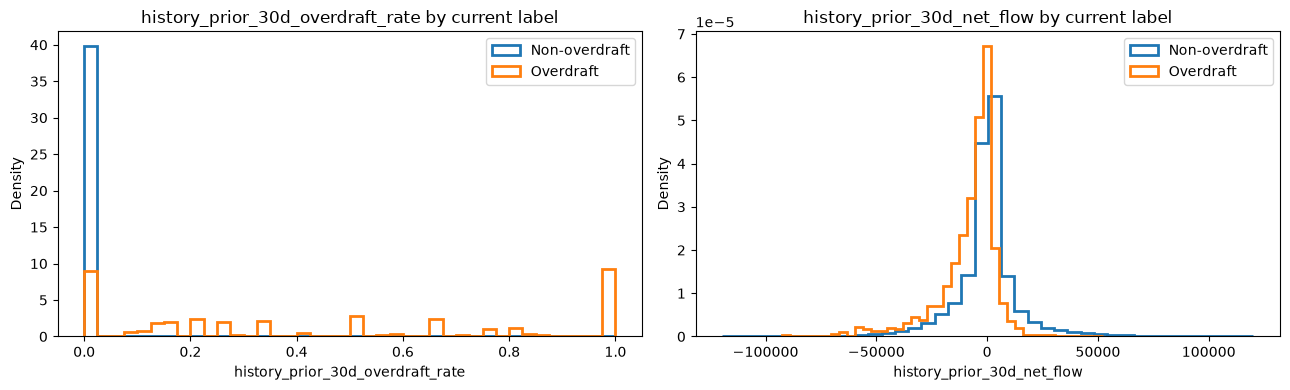

In [5]:
overdraft = raw_trans["balance"].lt(0).astype("int8")
feature_target_correlations = (
    engineered_features.assign(overdraft=overdraft)
    .corr(numeric_only=True)["overdraft"]
    .drop("overdraft")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
display_dataframe(
    pd.DataFrame(
        {
            "correlation_with_current_overdraft": feature_target_correlations,
            "mean_non_overdraft": engineered_features.loc[overdraft == 0].mean(),
            "mean_overdraft": engineered_features.loc[overdraft == 1].mean(),
        },
    ),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column in zip(
    axes,
    ["history_prior_30d_overdraft_rate", "history_prior_30d_net_flow"],
    strict=True,
):
    for label, label_name in [(0, "Non-overdraft"), (1, "Overdraft")]:
        values = engineered_features.loc[overdraft == label, column]
        ax.hist(values, bins=40, density=True, histtype="step", linewidth=2, label=label_name)
    ax.set(title=f"{column} by current label", xlabel=column, ylabel="Density")
    ax.legend()
fig.tight_layout()
plt.show()

## Convert to ClavaDDPM table format

Reuse the active dataset's saved date epoch and label encoders so the existing and new features share the same preprocessing conventions. The full raw history is transformed before any optional downstream sampling, which preserves account chronology for history features.

In [6]:
processed_trans, fitted_encoders, _ = preprocess_table("trans", raw_trans, trans_date_epoch)
for column, fitted_encoder in fitted_encoders.items():
    saved_encoder = saved_trans_encoders[column]
    if not np.array_equal(fitted_encoder.classes_, saved_encoder.classes_):
        raise ValueError(
            f"Category-code mapping differs from {BASE_DATA_DIR} for {column!r}; "
            "the enriched table would not align with existing runs.",
        )

if not np.array_equal(processed_trans["trans_id"].to_numpy(), raw_trans["trans_id"].to_numpy()):
    raise AssertionError("Preprocessing changed transaction row order; refusing unsafe feature join.")

FEATURE_COLUMNS = engineered_features.columns.tolist()
trans_enriched = pd.concat(
    [processed_trans.reset_index(drop=True), engineered_features.reset_index(drop=True)],
    axis=1,
)
if trans_enriched.columns.duplicated().any():
    raise ValueError("Enriched transaction table contains duplicate column names.")
print(f"Prepared ClavaDDPM trans table with {len(trans_enriched):,} rows and {trans_enriched.shape[1]} columns.")
print("Added columns:", FEATURE_COLUMNS)

Prepared ClavaDDPM trans table with 1,056,320 rows and 27 columns.
Added columns: ['calendar_weekday_sin', 'calendar_weekday_cos', 'calendar_month_sin', 'calendar_month_cos', 'history_days_since_previous_active_day', 'history_prior_7d_transaction_count', 'history_prior_7d_inflow', 'history_prior_7d_outflow', 'history_prior_7d_net_flow', 'history_prior_30d_transaction_count', 'history_prior_30d_inflow', 'history_prior_30d_outflow', 'history_prior_30d_net_flow', 'history_prior_30d_mean_amount', 'history_prior_30d_overdraft_count', 'history_prior_30d_overdraft_rate', 'amount_to_prior_30d_mean']


## Export a separate multi-table input dataset

The output directory is suitable as the `base_data_dir` for ClavaDDPM. All unchanged tables and metadata are copied from `BASE_DATA_DIR`; only the transaction table and its domain/preprocessing metadata are extended. The original input directory is never overwritten.

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if OUTPUT_DIR.resolve() == BASE_DATA_DIR.resolve():
    raise ValueError("Refusing to write enriched files over the base dataset.")

for table in ("account", "card", "client", "disp", "district", "loan", "order"):
    for suffix in (".csv", "_domain.json"):
        source = BASE_DATA_DIR / f"{table}{suffix}"
        if not source.is_file():
            raise FileNotFoundError(f"Required ClavaDDPM input is missing: {source}")
        shutil.copy2(source, OUTPUT_DIR / source.name)
for filename in ("dataset_meta.json", "label_encoders.pkl", "preprocess_meta.json"):
    source = BASE_DATA_DIR / filename
    if not source.is_file():
        raise FileNotFoundError(f"Required ClavaDDPM metadata is missing: {source}")
    shutil.copy2(source, OUTPUT_DIR / filename)

trans_enriched.to_csv(OUTPUT_DIR / "trans.csv", index=False)
with (BASE_DATA_DIR / "trans_domain.json").open(encoding="utf-8") as file:
    trans_domain = json.load(file)
for column in FEATURE_COLUMNS:
    trans_domain[column] = {"type": "continuous"}
with (OUTPUT_DIR / "trans_domain.json").open("w", encoding="utf-8") as file:
    json.dump(trans_domain, file, indent=4)
    file.write("\n")

with (OUTPUT_DIR / "preprocess_meta.json").open(encoding="utf-8") as file:
    output_meta = json.load(file)
trans_meta = output_meta["tables"]["trans"]
trans_meta["continuous_columns"].extend(FEATURE_COLUMNS)
trans_meta["output_columns"].extend(FEATURE_COLUMNS)
trans_meta["engineered_features"] = {
    "method": "strictly prior calendar-day transaction history",
    "source": str(RAW_TRANS_PATH),
    "columns": FEATURE_COLUMNS,
    "same_day_history_excluded": True,
    "current_balance_used_for_features": False,
}
with (OUTPUT_DIR / "preprocess_meta.json").open("w", encoding="utf-8") as file:
    json.dump(output_meta, file, indent=4)
    file.write("\n")

print(f"Wrote feature-enriched ClavaDDPM inputs to: {OUTPUT_DIR}")
print(f"Generated table: {OUTPUT_DIR / 'trans.csv'}")
print(f"Added continuous domain fields: {len(FEATURE_COLUMNS)}")

Wrote feature-enriched ClavaDDPM inputs to: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka_feature_engineered
Generated table: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka_feature_engineered/trans.csv
Added continuous domain fields: 17


## Use in ClavaDDPM and limitations

1. Train a separate ClavaDDPM run with `base_data_dir` pointing to the exported `berka_feature_engineered` directory. Keep the existing run and its data directory unchanged for a controlled comparison.
2. Generate synthetic transactions from that model, then evaluate overdraft transfer using `OverdraftTransferEvaluator` with the matching enriched real and synthetic transaction features. That evaluator currently expects the original feature set; extend it to include these new columns before using it for an enriched-feature comparison.
3. Compare transfer metrics and feature/label diagnostics against the baseline. Do not select settings by synthetic test performance alone; retain an account-held-out real validation/test evaluation.

These features are statistically derived, not independent evidence. Lagged overdraft history may be predictive by design; it is valid only when those prior transactions are available at prediction time. The source provides dates but not trustworthy within-day timestamps, so current-day history is excluded. Synthetic rows do not inherently form coherent chronological account sequences, and generation can still produce inconsistent combinations of history summaries and current transactions. Inspect those constraints in generated outputs before treating the added columns as reliable.